In [1]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import gc
import sys
from dotenv import load_dotenv

load_dotenv()
os.chdir(os.getenv("ROOT"))
sys.path.insert(0, os.getenv("ROOT"))

from src.experiment_notebook import setup_experiment, fine_tune_and_evaluate

In [2]:
# Archivo para guardar resultados incrementalmente
RESULTS_FILE = 'sweep_results.json'

In [3]:
# Cargar resultados (útil si se re-ejecuta solo esta celda)
with open(RESULTS_FILE, 'r') as f:
    all_results = json.load(f)

df_results = pd.DataFrame(all_results)
df_results = df_results.sort_values(['alpha', 'ls']).reset_index(drop=True)

# Mostrar tabla
display(df_results[['alpha', 'ls', 'accuracy', 'tpr_gap', 'tpr_male', 'tpr_female', 'auc_all']]
        .style.format({
            'accuracy': '{:.3f}',
            'tpr_gap': '{:.3f}',
            'tpr_male': '{:.3f}',
            'tpr_female': '{:.3f}',
            'auc_all': '{:.3f}'
        })
        .background_gradient(subset=['tpr_gap'], cmap='Reds')
        .background_gradient(subset=['accuracy'], cmap='Greens')
)

,alpha,ls,accuracy,tpr_gap,tpr_male,tpr_female,auc_all
0,0.100000,8,0.841,0.017,0.785,0.802,0.910
1,0.100000,16,0.823,0.022,0.744,0.765,0.891
2,0.100000,32,0.825,0.020,0.760,0.741,0.903
3,0.100000,48,0.823,0.059,0.719,0.778,0.893
4,0.250000,8,0.825,0.005,0.736,0.741,0.905
5,0.250000,16,0.834,0.059,0.769,0.827,0.894
6,0.250000,32,0.828,0.003,0.769,0.765,0.897
7,0.500000,8,0.834,0.030,0.760,0.790,0.905
8,0.500000,16,0.801,0.083,0.719,0.802,0.880
9,0.500000,32,0.825,0.005,0.736,0.741,0.889


/tmp/ipykernel_77156/2431064563.py:45: UserWarning: You passed a edgecolor/edgecolors ('black') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  axes[2].scatter(


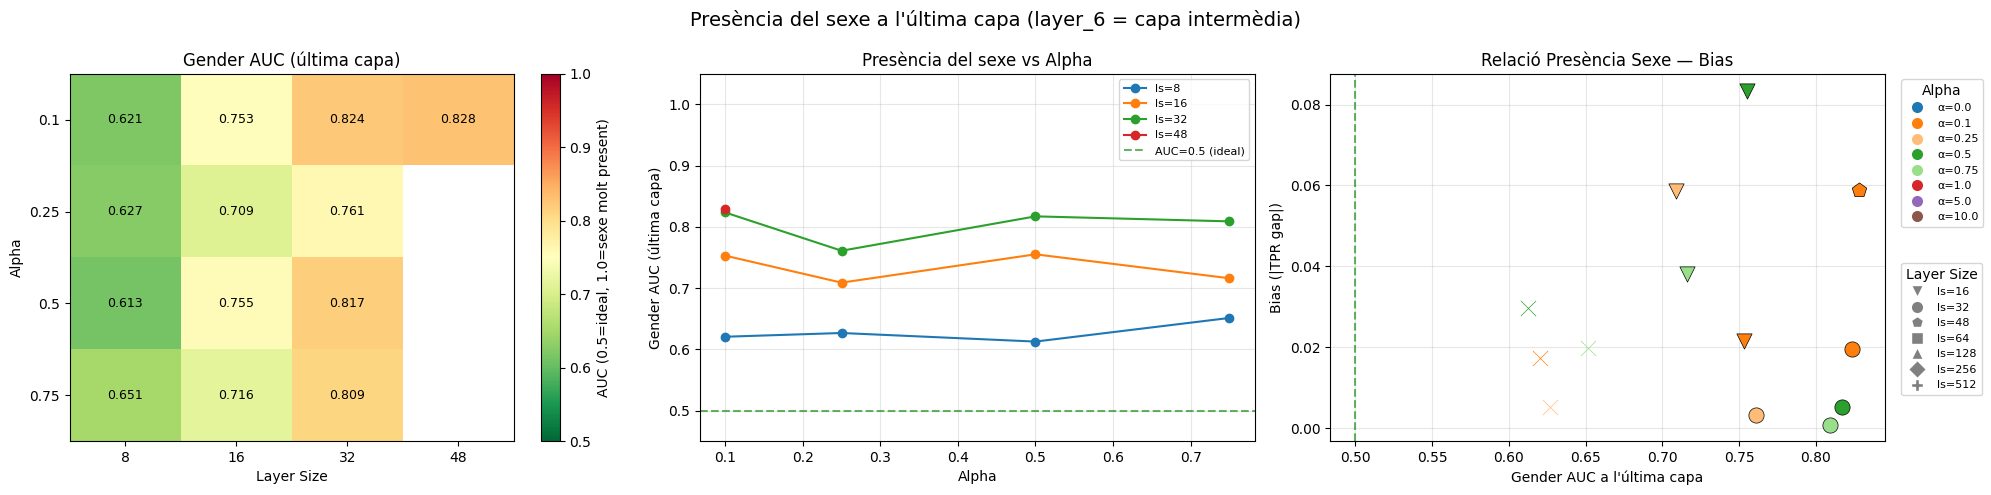

Gràfic guardat en gender_presence_last_layer.png


In [4]:
df_gender = df_results.dropna(subset=['gender_auc_last_layer']).copy()

if df_gender.empty:
    print("No hi ha dades de 'gender_auc_last_layer' als resultats.")
    print("Torna a executar el sweep (cel·la 3) per generar-les.")
else:
    fig, axes = plt.subplots(1, 3, figsize=(20, 5))

    # --- 1. Heatmap: Gender AUC a l'última capa per (alpha, ls) ---
    pivot_gauc = df_gender.pivot(index='alpha', columns='ls', values='gender_auc_last_layer')
    im = axes[0].imshow(pivot_gauc.values, cmap='RdYlGn_r', aspect='auto', vmin=0.5, vmax=1.0)
    axes[0].set_xticks(range(len(pivot_gauc.columns)))
    axes[0].set_xticklabels(pivot_gauc.columns)
    axes[0].set_yticks(range(len(pivot_gauc.index)))
    axes[0].set_yticklabels(pivot_gauc.index)
    axes[0].set_xlabel('Layer Size')
    axes[0].set_ylabel('Alpha')
    axes[0].set_title('Gender AUC (última capa)')
    for i in range(len(pivot_gauc.index)):
        for j in range(len(pivot_gauc.columns)):
            val = pivot_gauc.values[i, j]
            if not np.isnan(val):
                axes[0].text(j, i, f'{val:.3f}', ha='center', va='center', fontsize=9)
    plt.colorbar(im, ax=axes[0], label='AUC (0.5=ideal, 1.0=sexe molt present)')

    # --- 2. Corbes: Gender AUC vs Alpha per cada layer size ---
    for ls in sorted(df_gender['ls'].unique()):
        subset = df_gender[df_gender['ls'] == ls].sort_values('alpha')
        axes[1].plot(subset['alpha'], subset['gender_auc_last_layer'], marker='o', label=f'ls={ls}')
    axes[1].axhline(0.5, color='green', linestyle='--', alpha=0.6, label='AUC=0.5 (ideal)')
    axes[1].set_xlabel('Alpha')
    axes[1].set_ylabel('Gender AUC (última capa)')
    axes[1].set_title('Presència del sexe vs Alpha')
    axes[1].set_ylim(0.45, 1.05)
    axes[1].legend(fontsize=8)
    axes[1].grid(True, alpha=0.3)

    # --- 3. Scatter: Bias vs Gender AUC, color=alpha ---
    alpha_colors = {0.0: '#1f77b4', 0.1: '#ff7f0e', 0.25: '#ffbb78', 0.5: '#2ca02c',
                    0.75: '#98df8a', 1.0: '#d62728', 5.0: '#9467bd', 10.0: '#8c564b'}
    ls_markers = {16: 'v', 32: 'o', 48: 'p', 64: 's', 128: '^', 256: 'D', 512: 'P'}

    for _, row in df_gender.iterrows():
        a, l = row['alpha'], row['ls']
        axes[2].scatter(
            row['gender_auc_last_layer'], row['tpr_gap'],
            color=alpha_colors.get(a, 'gray'),
            marker=ls_markers.get(l, 'x'),
            s=120, edgecolors='black', linewidths=0.5, zorder=5
        )
    axes[2].axvline(0.5, color='green', linestyle='--', alpha=0.6, label='Gender AUC=0.5 (ideal)')
    axes[2].set_xlabel('Gender AUC a l\'última capa')
    axes[2].set_ylabel('Bias (|TPR gap|)')
    axes[2].set_title('Relació Presència Sexe — Bias')
    axes[2].grid(True, alpha=0.3)

    from matplotlib.lines import Line2D
    legend_alpha = [Line2D([0], [0], marker='o', color='w', markerfacecolor=c,
                           markersize=9, label=f'α={a}') for a, c in alpha_colors.items()]
    legend_ls = [Line2D([0], [0], marker=m, color='w', markerfacecolor='gray',
                        markersize=9, label=f'ls={l}') for l, m in ls_markers.items()]
    leg1 = axes[2].legend(handles=legend_alpha, title='Alpha', loc='upper left',
                          bbox_to_anchor=(1.02, 1), fontsize=8)
    axes[2].add_artist(leg1)
    axes[2].legend(handles=legend_ls, title='Layer Size', loc='upper left',
                   bbox_to_anchor=(1.02, 0.5), fontsize=8)

    plt.suptitle('Presència del sexe a l\'última capa (layer_6 = capa intermèdia)', fontsize=14)
    plt.tight_layout()
    plt.savefig('gender_presence_last_layer.png', dpi=150, bbox_inches='tight')
    plt.show()
    print("Gràfic guardat en gender_presence_last_layer.png")